<a href="https://colab.research.google.com/github/Mushfika123/Assignment/blob/main/Diabetes_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Download and load the dataset (more reliable method)
import pandas as pd

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"

column_names = [
    'Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness',
    'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'
]

df = pd.read_csv(url, header=None, names=column_names)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
df.head()

Dataset loaded successfully!
Shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Shape of dataset: (768, 9)

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB
None

Statistical Summary:
       Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count   768.000000  768.000000     768.000000     768.000000  768.000000   
mean      3.845052 

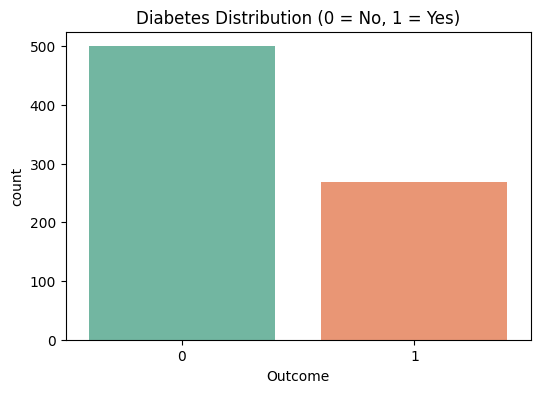

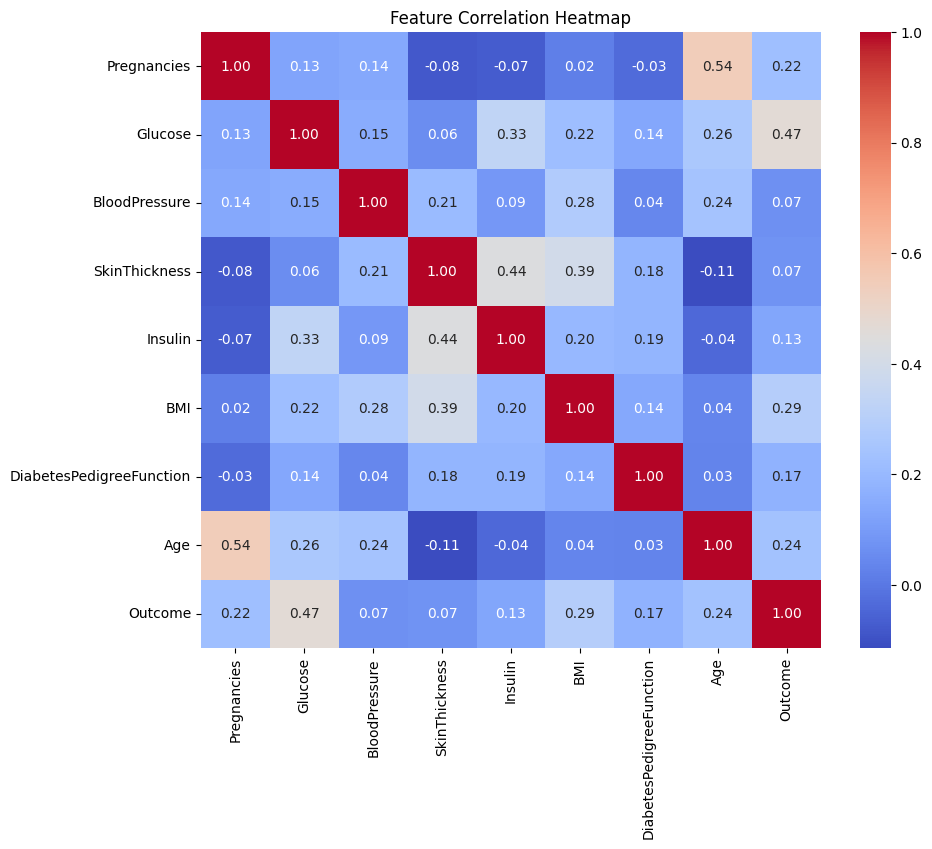

In [3]:
# Basic Information
print("Shape of dataset:", df.shape)
print("\nDataset Info:")
print(df.info())

print("\nStatistical Summary:")
print(df.describe())

print("\nMissing values (before handling):")
print(df.isnull().sum())

# Target Distribution
plt.figure(figsize=(6,4))
sns.countplot(x='Outcome', data=df, hue='Outcome', palette='Set2', legend=False)
plt.title("Diabetes Distribution (0 = No, 1 = Yes)")
plt.show()

# Correlation Heatmap
plt.figure(figsize=(10,8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Feature Correlation Heatmap")
plt.show()

In [4]:
# Replace 0 with NaN in columns where 0 is invalid
cols_with_zero = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df[cols_with_zero] = df[cols_with_zero].replace(0, np.nan)

print("Missing values after replacing 0 with NaN:")
print(df.isnull().sum())

# Separate features and target
X = df.drop('Outcome', axis=1)
y = df['Outcome']

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Handle missing values with median
imputer = SimpleImputer(strategy='median')
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

# Feature Scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("\nPreprocessing Completed Successfully!")
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

Missing values after replacing 0 with NaN:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

Preprocessing Completed Successfully!
X_train shape: (614, 8)
X_test shape: (154, 8)


In [5]:
# Train Random Forest model
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


Accuracy: 77.27%

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.86      0.83       100
           1       0.70      0.61      0.65        54

    accuracy                           0.77       154
   macro avg       0.75      0.74      0.74       154
weighted avg       0.77      0.77      0.77       154



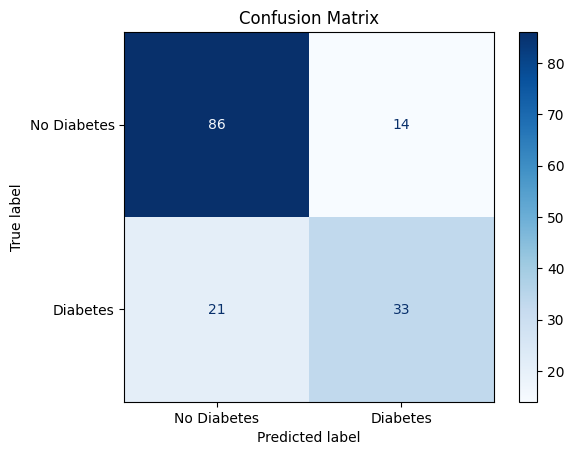

In [6]:
# Predictions
y_pred = model.predict(X_test)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy*100:.2f}%")

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Diabetes', 'Diabetes'])
disp.plot(cmap='Blues')
plt.title("Confusion Matrix")
plt.show()

In [7]:
def predict_diabetes(pregnancies, glucose, blood_pressure, skin_thickness,
                     insulin, bmi, dpf, age):

    input_data = np.array([[pregnancies, glucose, blood_pressure, skin_thickness,
                            insulin, bmi, dpf, age]])

    # Impute + Scale
    input_data = imputer.transform(input_data)
    input_data = scaler.transform(input_data)

    prediction = model.predict(input_data)[0]
    probability = model.predict_proba(input_data)[0][1]

    if prediction == 1:
        result = f"Diabetes Positive (Probability: {probability*100:.2f}%)"
    else:
        result = f"Diabetes Negative (Probability: {probability*100:.2f}%)"

    return result

# Example prediction
sample_result = predict_diabetes(6, 148, 72, 35, 0, 33.6, 0.627, 50)
print("Sample Prediction:", sample_result)

Sample Prediction: Diabetes Positive (Probability: 52.00%)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but SimpleImputer was fitted with feature names
  warnings.warn(


In [8]:
# ====================== COMPLETE FEATURE ENGINEERING CELL ======================

import pandas as pd
import numpy as np

# 1. Load the dataset again (so it works even after runtime restart)
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
column_names = [
    'Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness',
    'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'
]
df = pd.read_csv(url, header=None, names=column_names)

# 2. Replace invalid 0 values with NaN
cols_with_zero = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df[cols_with_zero] = df[cols_with_zero].replace(0, np.nan)

# 3. Create a copy for feature engineering
df_fe = df.copy()

# 4. New Feature 1: BMI Category
def bmi_category(bmi):
    if pd.isna(bmi):
        return np.nan
    elif bmi < 18.5:
        return 0      # Underweight
    elif bmi < 25:
        return 1      # Normal
    elif bmi < 30:
        return 2      # Overweight
    else:
        return 3      # Obese

df_fe['BMI_Category'] = df_fe['BMI'].apply(bmi_category)

# 5. New Feature 2: Age Group
def age_group(age):
    if age < 30:
        return 0      # Young
    elif age < 50:
        return 1      # Middle
    else:
        return 2      # Senior

df_fe['Age_Group'] = df_fe['Age'].apply(age_group)

# 6. Interaction Features
df_fe['Glucose_BMI'] = df_fe['Glucose'] * df_fe['BMI']
df_fe['Insulin_Glucose_Ratio'] = df_fe['Insulin'] / (df_fe['Glucose'] + 1)

# 7. Binary Risk Flags
df_fe['Is_High_BP'] = (df_fe['BloodPressure'] > 80).astype(float)
df_fe['Is_High_Glucose'] = (df_fe['Glucose'] > 140).astype(float)

# 8. Risk Score
df_fe['Risk_Score'] = (
    (df_fe['Glucose'] / 100) +
    (df_fe['BMI'] / 10) +
    (df_fe['Age'] / 20) +
    df_fe['DiabetesPedigreeFunction']
)

print("✅ Feature Engineering Completed Successfully!")
print("Original features + New features shape:", df_fe.shape)
print("\nNew columns added:")
print([col for col in df_fe.columns if col not in df.columns])

df_fe.head()

✅ Feature Engineering Completed Successfully!
Original features + New features shape: (768, 16)

New columns added:
['BMI_Category', 'Age_Group', 'Glucose_BMI', 'Insulin_Glucose_Ratio', 'Is_High_BP', 'Is_High_Glucose', 'Risk_Score']


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,BMI_Category,Age_Group,Glucose_BMI,Insulin_Glucose_Ratio,Is_High_BP,Is_High_Glucose,Risk_Score
0,6,148.0,72.0,35.0,NaN,33.6,0.627,50,1,3.0,2,4972.8,NaN,0.0,1.0,7.967
1,1,85.0,66.0,29.0,NaN,26.6,0.351,31,0,2.0,1,2261.0,NaN,0.0,0.0,5.411
2,8,183.0,64.0,NaN,NaN,23.3,0.672,32,1,1.0,1,4263.9,NaN,0.0,1.0,6.432
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0,2.0,0,2500.9,1.044444,0.0,0.0,4.917
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1,3.0,1,5904.7,1.217391,0.0,0.0,9.618


In [9]:
# Separate features and target
X = df_fe.drop('Outcome', axis=1)
y = df_fe['Outcome']

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Handle missing values
imputer = SimpleImputer(strategy='median')
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

# Scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Data ready with engineered features!")
print("X_train shape:", X_train.shape)

Data ready with engineered features!
X_train shape: (614, 15)


Data preparation completed!
X_train shape: (614, 15)

Accuracy: 72.73 %

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.79      0.79       100
           1       0.61      0.61      0.61        54

    accuracy                           0.73       154
   macro avg       0.70      0.70      0.70       154
weighted avg       0.73      0.73      0.73       154



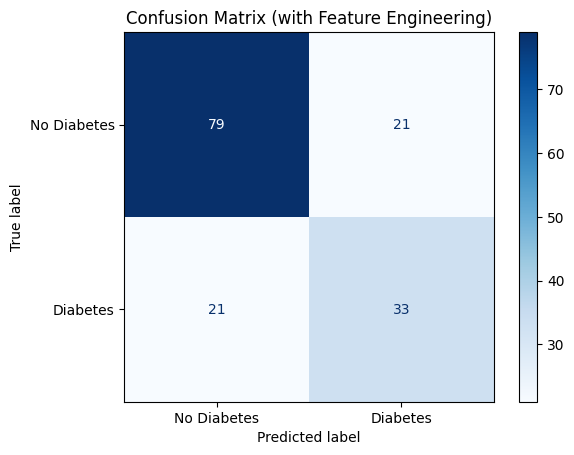


✅ Model training and evaluation completed successfully!


In [10]:
# ====================== COMPLETE TRAIN + EVALUATE CELL ======================

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# 1. Prepare features and target from df_fe
X = df_fe.drop('Outcome', axis=1)
y = df_fe['Outcome']

# 2. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Handle missing values
imputer = SimpleImputer(strategy='median')
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

# 4. Feature Scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Data preparation completed!")
print("X_train shape:", X_train.shape)

# 5. Train Stronger Random Forest Model
model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    random_state=42,
    class_weight='balanced'
)

model.fit(X_train, y_train)

# 6. Predictions
y_pred = model.predict(X_test)

# 7. Evaluation
print("\nAccuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# 8. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Diabetes', 'Diabetes'])
disp.plot(cmap='Blues')
plt.title("Confusion Matrix (with Feature Engineering)")
plt.show()

print("\n✅ Model training and evaluation completed successfully!")

                     Feature  Importance
10               Glucose_BMI    0.167049
14                Risk_Score    0.163278
1                    Glucose    0.128699
5                        BMI    0.086163
7                        Age    0.069720
6   DiabetesPedigreeFunction    0.069370
4                    Insulin    0.053572
0                Pregnancies    0.044536
13           Is_High_Glucose    0.044237
2              BloodPressure    0.043214
11     Insulin_Glucose_Ratio    0.042884
3              SkinThickness    0.040982
8               BMI_Category    0.018956
9                  Age_Group    0.018911
12                Is_High_BP    0.008429


/tmp/ipykernel_929/779999186.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feat_imp, palette='viridis')


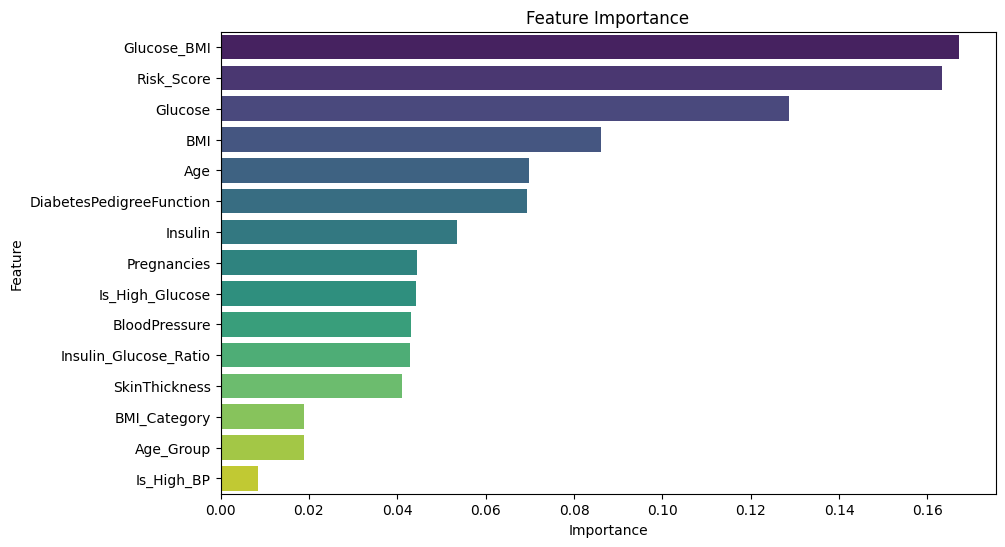

In [11]:
import pandas as pd

feature_names = X.columns
importances = model.feature_importances_

feat_imp = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

print(feat_imp)

plt.figure(figsize=(10,6))
sns.barplot(x='Importance', y='Feature', data=feat_imp, palette='viridis')
plt.title("Feature Importance")
plt.show()

In [12]:
!pip install xgboost -q

Starting Hyperparameter Tuning... (this may take 1-2 minutes)
Fitting 5 folds for each of 24 candidates, totalling 120 fits


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [08:54:12] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Best Parameters: {'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 200, 'subsample': 0.8}
Best Cross-Validation Score: 77.04 %

Test Accuracy: 71.43 %

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.83      0.79       100
           1       0.61      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.67      0.67       154
weighted avg       0.71      0.71      0.71       154



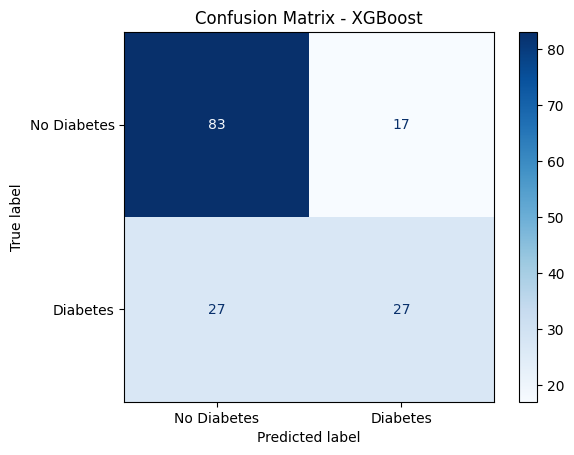

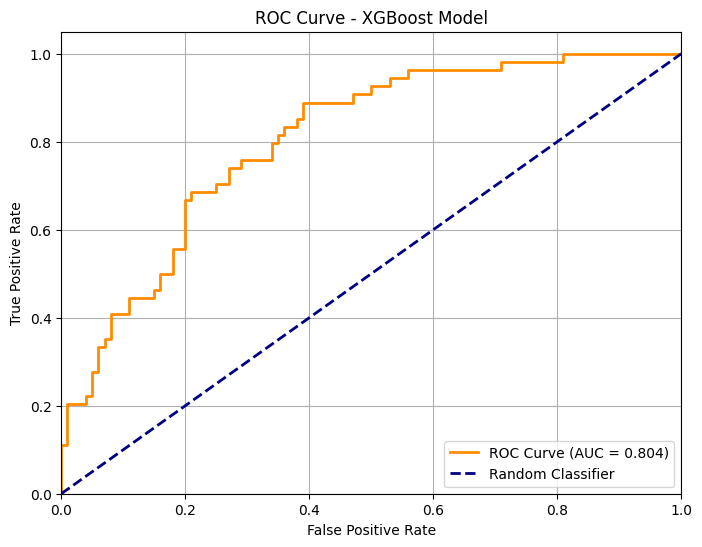


AUC Score: 0.8041

✅ XGBoost + Hyperparameter Tuning + ROC completed successfully!


In [13]:
# ====================== XGBoost + Tuning + ROC ======================

from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, auc, RocCurveDisplay)
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# ---------- 1. Prepare Data ----------
X = df_fe.drop('Outcome', axis=1)
y = df_fe['Outcome']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

imputer = SimpleImputer(strategy='median')
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# ---------- 2. Hyperparameter Tuning with GridSearchCV ----------
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.1],
    'subsample': [0.8, 1.0]
}

xgb = XGBClassifier(
    objective='binary:logistic',
    eval_metric='logloss',
    random_state=42,
    use_label_encoder=False
)

grid_search = GridSearchCV(
    estimator=xgb,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

print("Starting Hyperparameter Tuning... (this may take 1-2 minutes)")
grid_search.fit(X_train, y_train)

print("\nBest Parameters:", grid_search.best_params_)
print("Best Cross-Validation Score:", round(grid_search.best_score_ * 100, 2), "%")

# ---------- 3. Best Model ----------
best_model = grid_search.best_estimator_

y_pred = best_model.predict(X_test)
y_pred_proba = best_model.predict_proba(X_test)[:, 1]

# ---------- 4. Evaluation ----------
print("\nTest Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Diabetes', 'Diabetes'])
disp.plot(cmap='Blues')
plt.title("Confusion Matrix - XGBoost")
plt.show()

# ---------- 5. ROC Curve + AUC ----------
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Classifier')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - XGBoost Model')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

print(f"\nAUC Score: {roc_auc:.4f}")
print("\n✅ XGBoost + Hyperparameter Tuning + ROC completed successfully!")

In [21]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report
import pandas as pd

# Data already prepared (X_train, X_test, y_train, y_test আছে ধরে নিচ্ছি)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=200, max_depth=5, learning_rate=0.1,
                             random_state=42, eval_metric='logloss', use_label_encoder=False)
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba)

    results.append({
        "Model": name,
        "Accuracy": round(acc * 100, 2),
        "AUC Score": round(auc, 4)
    })

    print(f"\n{name}")
    print("Accuracy:", round(acc * 100, 2), "%")
    print("AUC:", round(auc, 4))
    print(classification_report(y_test, y_pred))

# Comparison Table
results_df = pd.DataFrame(results)
print("\n========== Model Comparison ==========")
print(results_df)


Logistic Regression
Accuracy: 71.43 %
AUC: 0.8293
              precision    recall  f1-score   support

           0       0.76      0.81      0.79       100
           1       0.60      0.54      0.57        54

    accuracy                           0.71       154
   macro avg       0.68      0.67      0.68       154
weighted avg       0.71      0.71      0.71       154


Random Forest
Accuracy: 73.38 %
AUC: 0.8127
              precision    recall  f1-score   support

           0       0.78      0.83      0.80       100
           1       0.64      0.56      0.59        54

    accuracy                           0.73       154
   macro avg       0.71      0.69      0.70       154
weighted avg       0.73      0.73      0.73       154


XGBoost
Accuracy: 77.92 %
AUC: 0.8307
              precision    recall  f1-score   support

           0       0.82      0.85      0.83       100
           1       0.70      0.65      0.67        54

    accuracy                           0.78    

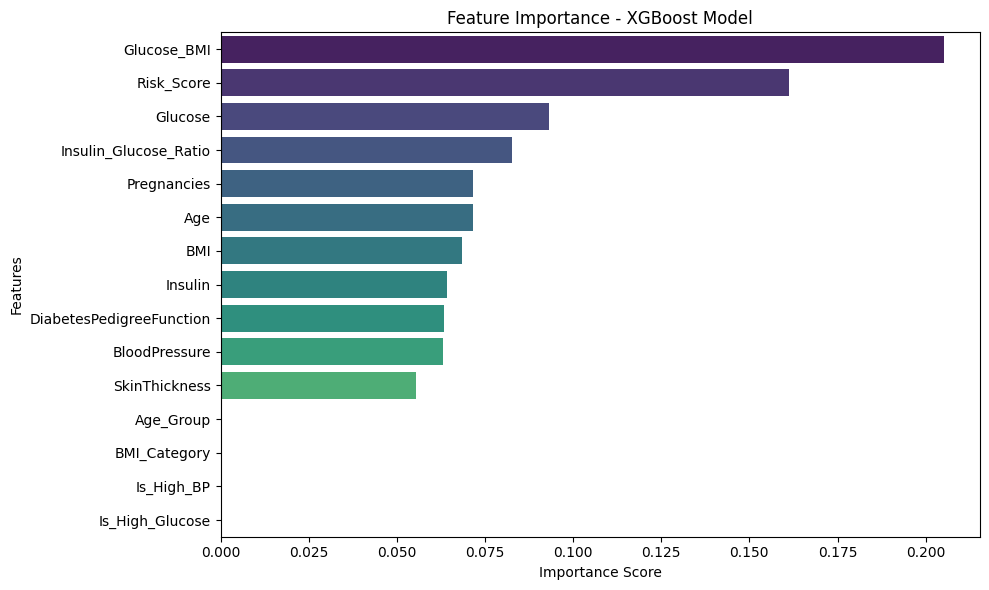

                     Feature  Importance
10               Glucose_BMI    0.205160
14                Risk_Score    0.161336
1                    Glucose    0.093151
11     Insulin_Glucose_Ratio    0.082622
0                Pregnancies    0.071692
7                        Age    0.071511
5                        BMI    0.068593
4                    Insulin    0.064135
6   DiabetesPedigreeFunction    0.063425
2              BloodPressure    0.062965
3              SkinThickness    0.055410
9                  Age_Group    0.000000
8               BMI_Category    0.000000
12                Is_High_BP    0.000000
13           Is_High_Glucose    0.000000


In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

# XGBoost model already trained আছে ধরে নিচ্ছি
importances = model.feature_importances_
features = X.columns

feat_imp = pd.DataFrame({
    'Feature': features,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feat_imp, palette='viridis')
plt.title("Feature Importance - XGBoost Model")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

print(feat_imp)

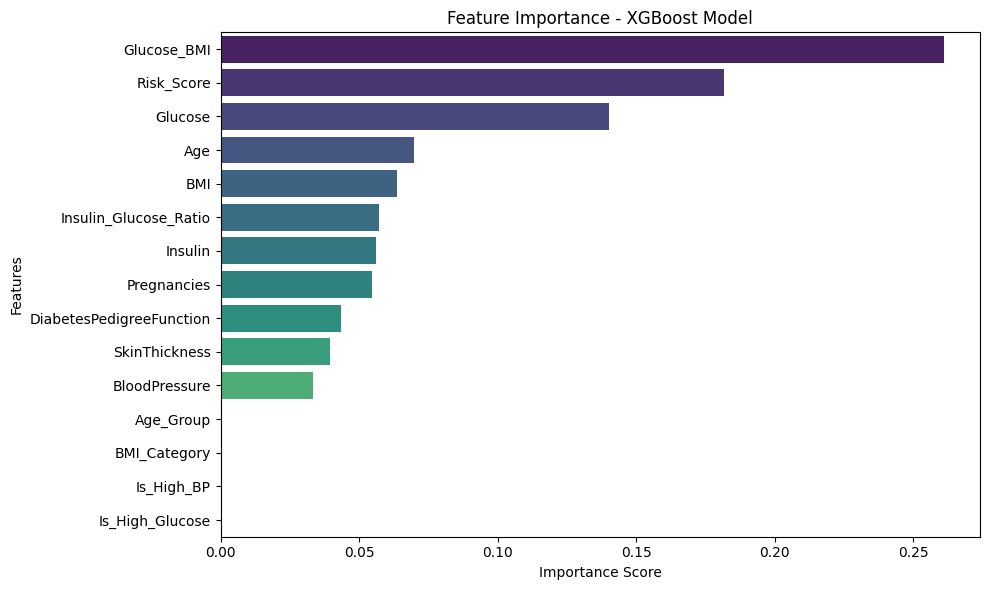

                     Feature  Importance
10               Glucose_BMI    0.261080
14                Risk_Score    0.181603
1                    Glucose    0.140285
7                        Age    0.069681
5                        BMI    0.063519
11     Insulin_Glucose_Ratio    0.057089
4                    Insulin    0.055999
0                Pregnancies    0.054506
6   DiabetesPedigreeFunction    0.043346
3              SkinThickness    0.039622
2              BloodPressure    0.033270
9                  Age_Group    0.000000
8               BMI_Category    0.000000
12                Is_High_BP    0.000000
13           Is_High_Glucose    0.000000


In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# XGBoost model already trained আছে ধরে নিচ্ছি (best_model বা model)
importances = best_model.feature_importances_
features = X.columns

feat_imp = pd.DataFrame({
    'Feature': features,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feat_imp, palette='viridis')
plt.title("Feature Importance - XGBoost Model")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

print(feat_imp)

In [25]:
!pip install gradio xgboost scikit-learn pandas numpy -q

In [26]:
import gradio as gr
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score
import warnings
warnings.filterwarnings('ignore')

# ====================== Load Data + Feature Engineering + Train Model ======================

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
column_names = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness',
                'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']
df = pd.read_csv(url, header=None, names=column_names)

# Handle zeros
cols_with_zero = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df[cols_with_zero] = df[cols_with_zero].replace(0, np.nan)

# Feature Engineering
def bmi_category(bmi):
    if pd.isna(bmi): return np.nan
    elif bmi < 18.5: return 0
    elif bmi < 25: return 1
    elif bmi < 30: return 2
    else: return 3

def age_group(age):
    if age < 30: return 0
    elif age < 50: return 1
    else: return 2

df['BMI_Category'] = df['BMI'].apply(bmi_category)
df['Age_Group'] = df['Age'].apply(age_group)
df['Glucose_BMI'] = df['Glucose'] * df['BMI']
df['Insulin_Glucose_Ratio'] = df['Insulin'] / (df['Glucose'] + 1)
df['Is_High_BP'] = (df['BloodPressure'] > 80).astype(float)
df['Is_High_Glucose'] = (df['Glucose'] > 140).astype(float)
df['Risk_Score'] = (df['Glucose']/100) + (df['BMI']/10) + (df['Age']/20) + df['DiabetesPedigreeFunction']

X = df.drop('Outcome', axis=1)
y = df['Outcome']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

imputer = SimpleImputer(strategy='median')
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.1,
    subsample=0.8,
    random_state=42,
    eval_metric='logloss',
    use_label_encoder=False
)
model.fit(X_train, y_train)

accuracy = accuracy_score(y_test, model.predict(X_test))
print(f"Model Accuracy: {accuracy*100:.2f}%")

feature_names = X.columns.tolist()

# ====================== Prediction Function ======================

def predict_diabetes(pregnancies, glucose, blood_pressure, skin_thickness, insulin, bmi, dpf, age):

    input_df = pd.DataFrame([{
        'Pregnancies': pregnancies,
        'Glucose': glucose,
        'BloodPressure': blood_pressure,
        'SkinThickness': skin_thickness,
        'Insulin': insulin,
        'BMI': bmi,
        'DiabetesPedigreeFunction': dpf,
        'Age': age
    }])

    # Feature Engineering
    input_df['BMI_Category'] = input_df['BMI'].apply(bmi_category)
    input_df['Age_Group'] = input_df['Age'].apply(age_group)
    input_df['Glucose_BMI'] = input_df['Glucose'] * input_df['BMI']
    input_df['Insulin_Glucose_Ratio'] = input_df['Insulin'] / (input_df['Glucose'] + 1)
    input_df['Is_High_BP'] = (input_df['BloodPressure'] > 80).astype(float)
    input_df['Is_High_Glucose'] = (input_df['Glucose'] > 140).astype(float)
    input_df['Risk_Score'] = (input_df['Glucose']/100) + (input_df['BMI']/10) + (input_df['Age']/20) + input_df['DiabetesPedigreeFunction']

    input_df = input_df[feature_names]

    input_imputed = imputer.transform(input_df)
    input_scaled = scaler.transform(input_imputed)

    prediction = model.predict(input_scaled)[0]
    probability = model.predict_proba(input_scaled)[0][1] * 100

    if prediction == 1:
        result = f"⚠️ High Risk: Diabetes Positive"
        color = "risk"
    else:
        result = f"✅ Low Risk: Diabetes Negative"
        color = "safe"

    return result, f"{probability:.2f}%"

# ====================== Gradio Interface ======================

with gr.Blocks(title="Diabetes Prediction System") as demo:
    gr.Markdown("# 🩺 Advanced Diabetes Prediction System")
    gr.Markdown("### Feature Engineering + XGBoost")
    gr.Markdown(f"**Model Accuracy:** {accuracy*100:.2f}%")

    with gr.Row():
        with gr.Column():
            pregnancies = gr.Number(label="Pregnancies", value=1, minimum=0, maximum=20)
            glucose = gr.Number(label="Glucose", value=120, minimum=0, maximum=300)
            blood_pressure = gr.Number(label="Blood Pressure", value=70, minimum=0, maximum=150)
            skin_thickness = gr.Number(label="Skin Thickness", value=20, minimum=0, maximum=100)

        with gr.Column():
            insulin = gr.Number(label="Insulin", value=80, minimum=0, maximum=900)
            bmi = gr.Number(label="BMI", value=25.0, minimum=0, maximum=70)
            dpf = gr.Number(label="Diabetes Pedigree Function", value=0.5, minimum=0, maximum=3)
            age = gr.Number(label="Age", value=30, minimum=1, maximum=120)

    predict_btn = gr.Button("Predict Diabetes Risk", variant="primary")

    with gr.Row():
        result_output = gr.Textbox(label="Prediction Result")
        probability_output = gr.Textbox(label="Probability of Diabetes")

    predict_btn.click(
        fn=predict_diabetes,
        inputs=[pregnancies, glucose, blood_pressure, skin_thickness, insulin, bmi, dpf, age],
        outputs=[result_output, probability_output]
    )

    gr.Markdown("---")
    gr.Markdown("⚠️ **Disclaimer:** This is only a machine learning prediction. Please consult a doctor for medical advice.")

# Launch the app
demo.launch(share=True)

Model Accuracy: 76.62%
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://455962ee800dbe60b8.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [27]:
import gradio as gr
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score
import warnings
warnings.filterwarnings('ignore')

# ====================== Load Data + Feature Engineering + Train Model ======================

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
column_names = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness',
                'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']
df = pd.read_csv(url, header=None, names=column_names)

cols_with_zero = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df[cols_with_zero] = df[cols_with_zero].replace(0, np.nan)

def bmi_category(bmi):
    if pd.isna(bmi): return np.nan
    elif bmi < 18.5: return 0
    elif bmi < 25: return 1
    elif bmi < 30: return 2
    else: return 3

def age_group(age):
    if age < 30: return 0
    elif age < 50: return 1
    else: return 2

df['BMI_Category'] = df['BMI'].apply(bmi_category)
df['Age_Group'] = df['Age'].apply(age_group)
df['Glucose_BMI'] = df['Glucose'] * df['BMI']
df['Insulin_Glucose_Ratio'] = df['Insulin'] / (df['Glucose'] + 1)
df['Is_High_BP'] = (df['BloodPressure'] > 80).astype(float)
df['Is_High_Glucose'] = (df['Glucose'] > 140).astype(float)
df['Risk_Score'] = (df['Glucose']/100) + (df['BMI']/10) + (df['Age']/20) + df['DiabetesPedigreeFunction']

X = df.drop('Outcome', axis=1)
y = df['Outcome']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

imputer = SimpleImputer(strategy='median')
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = XGBClassifier(
    n_estimators=200, max_depth=5, learning_rate=0.1,
    subsample=0.8, random_state=42, eval_metric='logloss', use_label_encoder=False
)
model.fit(X_train, y_train)

accuracy = accuracy_score(y_test, model.predict(X_test))
feature_names = X.columns.tolist()

# Feature importance for contribution
feature_importance = model.feature_importances_
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': feature_importance
}).sort_values(by='Importance', ascending=False)

# ====================== Prediction Function ======================

def predict_diabetes(pregnancies, glucose, blood_pressure, skin_thickness, insulin, bmi, dpf, age):
    input_df = pd.DataFrame([{
        'Pregnancies': pregnancies,
        'Glucose': glucose,
        'BloodPressure': blood_pressure,
        'SkinThickness': skin_thickness,
        'Insulin': insulin,
        'BMI': bmi,
        'DiabetesPedigreeFunction': dpf,
        'Age': age
    }])

    input_df['BMI_Category'] = input_df['BMI'].apply(bmi_category)
    input_df['Age_Group'] = input_df['Age'].apply(age_group)
    input_df['Glucose_BMI'] = input_df['Glucose'] * input_df['BMI']
    input_df['Insulin_Glucose_Ratio'] = input_df['Insulin'] / (input_df['Glucose'] + 1)
    input_df['Is_High_BP'] = (input_df['BloodPressure'] > 80).astype(float)
    input_df['Is_High_Glucose'] = (input_df['Glucose'] > 140).astype(float)
    input_df['Risk_Score'] = (input_df['Glucose']/100) + (input_df['BMI']/10) + (input_df['Age']/20) + input_df['DiabetesPedigreeFunction']

    input_df = input_df[feature_names]
    input_imputed = imputer.transform(input_df)
    input_scaled = scaler.transform(input_imputed)

    prediction = model.predict(input_scaled)[0]
    probability = model.predict_proba(input_scaled)[0][1] * 100

    # Better Result with Emoji + Color logic
    if probability >= 70:
        result = "🔴 Very High Risk: Diabetes Positive"
        interpretation = "Very high chance of diabetes. Immediate medical consultation is strongly recommended."
    elif probability >= 45:
        result = "🟠 High Risk: Diabetes Positive"
        interpretation = "High chance of diabetes. Please consult a doctor soon."
    elif probability >= 25:
        result = "🟡 Medium Risk"
        interpretation = "Moderate risk detected. Maintain healthy lifestyle and monitor regularly."
    else:
        result = "🟢 Low Risk: Diabetes Negative"
        interpretation = "Low chance of diabetes. Keep maintaining a healthy lifestyle."

    # Top Contributing Factors (simple version)
    top_features = importance_df.head(5)['Feature'].tolist()
    contribution_text = "Top factors influencing the prediction:\n"
    for i, feat in enumerate(top_features, 1):
        contribution_text += f"{i}. {feat}\n"

    return result, f"{probability:.2f}%", interpretation, probability, contribution_text

# ====================== Helper Functions ======================

def load_low_risk():
    return 1, 95, 70, 20, 80, 22.5, 0.3, 25

def load_medium_risk():
    return 3, 130, 78, 28, 120, 28.0, 0.5, 40

def load_high_risk():
    return 6, 160, 90, 35, 180, 34.5, 0.8, 52

def reset_inputs():
    return 1, 120, 70, 20, 80, 25.0, 0.5, 30

# ====================== Gradio Interface ======================

with gr.Blocks(title="Diabetes Prediction System", theme=gr.themes.Soft()) as demo:

    gr.Markdown("# 🩺 Advanced Diabetes Prediction System")
    gr.Markdown("### Feature Engineering + XGBoost")
    gr.Markdown(f"**Model Accuracy:** {accuracy*100:.2f}%")

    with gr.Row():
        example_low = gr.Button("🟢 Low Risk Example")
        example_medium = gr.Button("🟡 Medium Risk Example")
        example_high = gr.Button("🔴 High Risk Example")
        reset_btn = gr.Button("🔄 Reset All", variant="secondary")

    with gr.Row():
        with gr.Column():
            pregnancies = gr.Number(label="Pregnancies", value=1)
            glucose = gr.Number(label="Glucose", value=120)
            blood_pressure = gr.Number(label="Blood Pressure", value=70)
            skin_thickness = gr.Number(label="Skin Thickness", value=20)
        with gr.Column():
            insulin = gr.Number(label="Insulin", value=80)
            bmi = gr.Number(label="BMI", value=25.0)
            dpf = gr.Number(label="Diabetes Pedigree Function", value=0.5)
            age = gr.Number(label="Age", value=30)

    predict_btn = gr.Button("🔍 Predict Diabetes Risk", variant="primary", size="lg")

    with gr.Row():
        result_output = gr.Textbox(label="Prediction Result", interactive=False)
        probability_output = gr.Textbox(label="Probability of Diabetes", interactive=False)

    interpretation_output = gr.Textbox(label="Interpretation", interactive=False)
    risk_bar = gr.Slider(label="Risk Level Indicator", minimum=0, maximum=100, value=0, interactive=False)
    contribution_output = gr.Textbox(label="Top Contributing Factors", interactive=False, lines=6)

    # Button Actions
    example_low.click(fn=load_low_risk, outputs=[pregnancies, glucose, blood_pressure, skin_thickness, insulin, bmi, dpf, age])
    example_medium.click(fn=load_medium_risk, outputs=[pregnancies, glucose, blood_pressure, skin_thickness, insulin, bmi, dpf, age])
    example_high.click(fn=load_high_risk, outputs=[pregnancies, glucose, blood_pressure, skin_thickness, insulin, bmi, dpf, age])
    reset_btn.click(fn=reset_inputs, outputs=[pregnancies, glucose, blood_pressure, skin_thickness, insulin, bmi, dpf, age])

    predict_btn.click(
        fn=predict_diabetes,
        inputs=[pregnancies, glucose, blood_pressure, skin_thickness, insulin, bmi, dpf, age],
        outputs=[result_output, probability_output, interpretation_output, risk_bar, contribution_output]
    )

    gr.Markdown("---")
    gr.Markdown("⚠️ **Disclaimer:** This is only a machine learning prediction. Please consult a doctor for medical advice.")

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://115a82ed7c9f3e7563.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
